Saved messy_churn.csv: (10290, 14)


,RowNumber,Customer ID,Surname,credit_score,Geography,Gender,Age,Tenure,Balance,Num Of Products,Has Credit Card,Active Member?,Estimated Salary,Exited
0,248,15618311,Brown,738.0,Spain,Male,33.0,8.0,157301.96,2,1,0,161703.68,0
1,5260,15629951,Rossi,670.0,Germany,Male,30.0,1.0,162658.66,1,No,Y,6630.42,1
2,5477,15807215,Chen,705.0,Spain,Female,42.0,3.0,0.0,2,0,0,8993.63,Yes
3,8395,15786076,Martin,672.0,France,Male,49.0,8.0,145176.44,2,1,1,"$121,188.00",0
4,7192,15760596,Silva,709.0,France,Female,35.0,8.0,0.0,4,Yes,N,164314.42,Yes
5,539,15661899,Rossi,513.0,Germany,Male,26.0,10.0,141540.42,2,Yes,N,96861.85,0
6,6389,15733182,Kim,775.0,Spain,Female,35.0,6.0,189626.52,2,No,1,82689.37,0
7,5640,15566863,Lopez,594.0,Spain,Male,33.0,0.0,0.0,1,0,0,"$46,222.99",No
8,4750,15601526,Muller,635.0,Spain,Male,52.0,1.0,0.0,1,Yes,0,134556.06,1
9,9421,15590359,Brown,843.0,Spain,Male,37.0,8.0,94270.11,2,Yes,0,107281.29,0


Shape: (10290, 14)
Duplicate rows: 252 | Duplicate Customer IDs: 290

Missing values:
 credit_score        204
Geography           123
Gender               82
Age                 259
Tenure              102
Balance             154
Estimated Salary     60
dtype: int64

Data types:
 RowNumber             int64
Customer ID           int64
Surname              object
credit_score        float64
Geography            object
Gender               object
Age                 float64
Tenure              float64
Balance              object
Num Of Products       int64
Has Credit Card      object
Active Member?       object
Estimated Salary     object
Exited               object
dtype: object

Geography: {'France': 4476, 'Spain': 2260, 'Germany': 2156, 'FRANCE': 143, ' France ': 131, nan: 123, 'France ': 118, 'Fra.': 115, 'france': 110, 'GERMANY': 78, 'Ger.': 76, 'germany': 72, 'Spa.': 70, ' Spain ': 67, 'Spain ': 66, 'SPAIN': 59, 'Germany ': 58, 'spain': 57, ' Germany ': 55}

Gender: {'Male': 4871,

,count,mean,std,min,25%,50%,75%,max
RowNumber,10290.0,5.145500e+03,2970.611469,1.0,2573.25,5145.5,7717.75,10290.0
Customer ID,10290.0,1.568876e+07,71779.176613,15565000.0,15626276.75,15688020.0,15750860.75,15814990.0
credit_score,10086.0,6.551839e+02,229.422558,-50.0,586.00,650.5,717.00,9999.0
Age,10031.0,3.952846e+01,25.569972,-1.0,32.00,37.0,45.00,999.0
Tenure,10188.0,5.075285e+00,3.631760,-3.0,2.00,5.0,8.00,99.0
Num Of Products,10290.0,1.528183e+00,0.579254,1.0,1.00,1.0,2.00,4.0


Removed 290 duplicate rows
Saved cleaned_churn.csv: (10000, 14) | Remaining missing values: 0


,customer_id,credit_score,geography,gender,age,tenure,balance,num_products,has_card,is_active,salary,exited,age_band,has_balance
0,15618311,738,Spain,Male,33,8,157301.96,2,1,0,161703.68,0,30-39,1
1,15629951,670,Germany,Male,30,1,162658.66,1,0,1,6630.42,1,30-39,1
2,15807215,705,Spain,Female,42,3,0.0,2,0,0,8993.63,1,40-49,0
3,15786076,672,France,Male,49,8,145176.44,2,1,1,121188.0,0,40-49,1
4,15760596,709,France,Female,35,8,0.0,4,1,0,164314.42,1,30-39,0


                messy  cleaned
rows            10290    10000
missing cells     984        0
duplicate rows    252        0
All checks passed
Customers: 10,000 | Churned: 2,036 (20.4%)


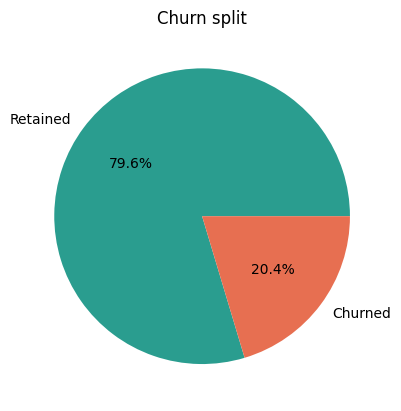

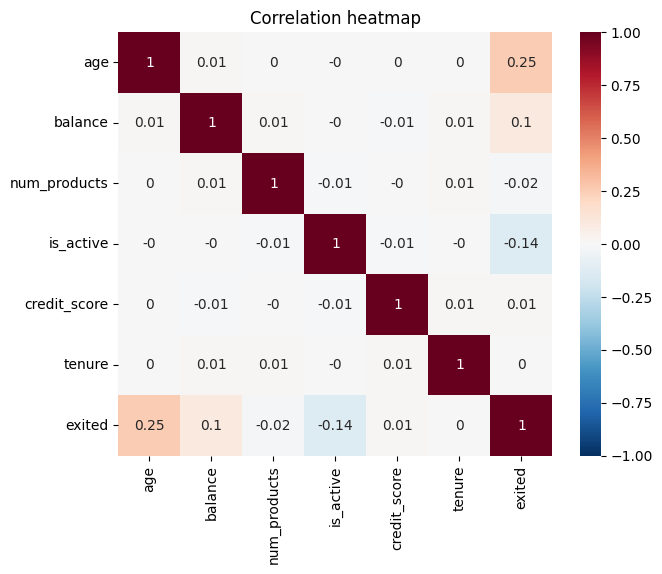

age             0.25
is_active      -0.14
balance         0.10
num_products   -0.02
credit_score    0.01
tenure          0.00
Name: exited, dtype: float64
geography
France     16.5
Germany    31.7
Spain      17.2
Name: churn %, dtype: float64 

gender
Female    24.2
Male      17.2
Name: churn %, dtype: float64 

is_active
0    26.1
1    14.9
Name: churn %, dtype: float64 



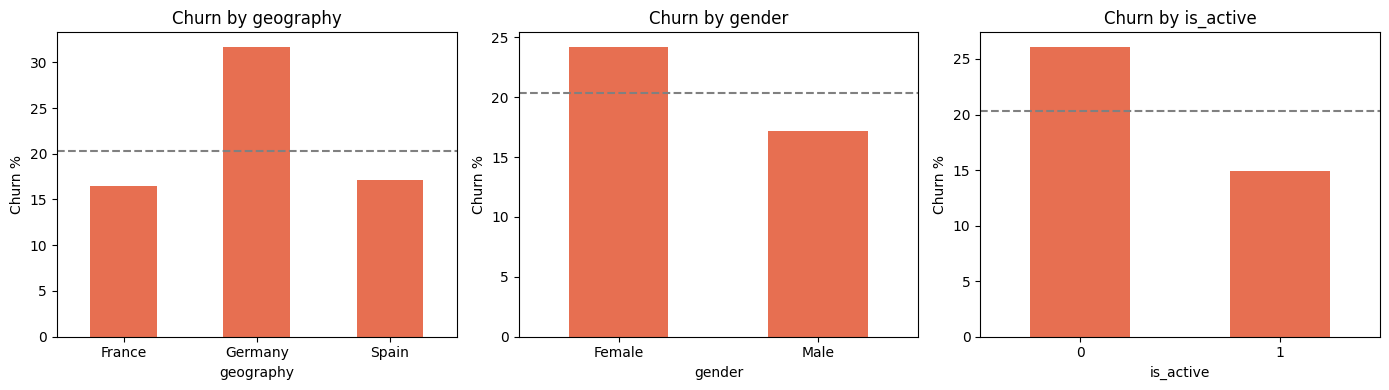

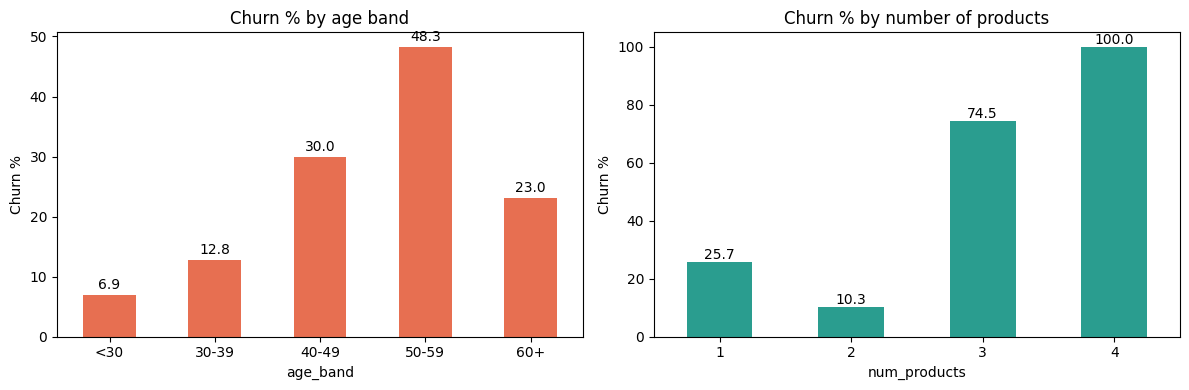

num_products
1    5102
2    4572
3     275
4      51
Name: customers (very few hold 3-4 products), dtype: int64
                     count  churn_rate
geography is_active                   
Germany   0           1196        39.1
          1           1239        24.5
Spain     0           1214        22.2
France    0           2472        21.7
Spain     1           1293        12.5
France    1           2586        11.5


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.optimize import brentq


# # Bank Customer Churn Analysis – Messy → Cleaned data
# Matches the slide deck: 10,000 customers, 10 attributes, ~20.4% churn.
#
# **Step 1** builds a *messy* dataset (realistic data-quality problems).
# **Step 2–4** inspect, clean and verify it.
# **Step 5** reproduces the deck's analysis (churn rates, correlations, charts).
#
# > The public *Churn Modelling* CSV (Kaggle) can be used instead: upload it in Step 1b and skip 1a. The cleaning code works on both.

# ## 1a. Create the messy dataset

import numpy as np, pandas as pd
from scipy.optimize import brentq
def make(seed=42, n=10000, params=None):
    rng=np.random.default_rng(seed)
    d=pd.DataFrame({'CustomerId':rng.choice(np.arange(15565000,15815000),n,replace=False)})
    d['Surname']=rng.choice(['Smith','Chen','Martin','Garcia','Okafor','Rossi','Singh','Muller','Lopez','Brown','Kim','Silva'],n)
    d['CreditScore']=np.clip(rng.normal(650,97,n),350,850).round().astype(int)
    d['Geography']=rng.choice(['France','Germany','Spain'],n,p=[.5014,.2509,.2477])
    d['Gender']=rng.choice(['Male','Female'],n,p=[.5457,.4543])
    d['Age']=np.clip(rng.gamma(4.4,4.8,n)+18,18,92).round().astype(int)
    d['Tenure']=rng.integers(0,11,n)
    bal=np.clip(rng.normal(122000,30000,n),3000,250000)
    d['Balance']=np.where(rng.random(n)<np.where(d.Geography=='Germany',0.0,0.52),0,bal).round(2)
    d['NumOfProducts']=rng.choice([1,2,3,4],n,p=[.5084,.4590,.0266,.006])
    d['HasCrCard']=rng.choice([0,1],n,p=[.2945,.7055])
    d['IsActiveMember']=rng.choice([0,1],n,p=[.4849,.5151])
    d['EstimatedSalary']=rng.uniform(11,200000,n).round(2)
    P=params or dict(g=1.0,f=.62,i=1.0)
    ageoff=pd.cut(d.Age,[0,29,39,49,59,200],labels=[-2.51,-1.99,-.66,.24,-1.10]).astype(float)
    prod=d.NumOfProducts.map({1:0,2:-1.4,3:2.6,4:7}).astype(float)
    z=ageoff+prod+np.where(d.Geography=='Germany',P['g'],0)+np.where(d.Gender=='Female',P['f'],0)+np.where(d.IsActiveMember==0,P['i'],0)+d.Balance/250000*0.3
    f=lambda b:(1/(1+np.exp(-(z+b)))).mean()-.1985
    b=brentq(f,-5,5); p=1/(1+np.exp(-(z+b)))
    d['Exited']=(rng.random(n)<p).astype(int)
    return d

rng = np.random.default_rng(7)
raw = make()                      # "truth" with ~20.4% churn
m = raw.copy()

# 1. inconsistent column names
m = m.rename(columns={"CustomerId":"Customer ID","CreditScore":"credit_score","NumOfProducts":"Num Of Products",
                      "IsActiveMember":"Active Member?","HasCrCard":"Has Credit Card","EstimatedSalary":"Estimated Salary"})

# 2. inconsistent text labels (case, spaces, abbreviations)
geo = m["Geography"].astype(object)
idx = rng.choice(m.index, 1500, replace=False)
geo.loc[idx] = [rng.choice([g.lower(), g.upper(), " "+g+" ", g+" ", g[:3]+".", g]) for g in geo.loc[idx]]
m["Geography"] = geo
gen_ = m["Gender"].astype(object)
idx = rng.choice(m.index, 1200, replace=False)
gen_.loc[idx] = [rng.choice(["M","male","MALE"," Male"]) if g=="Male" else rng.choice(["F","female","FEMALE","Female "]) for g in gen_.loc[idx]]
m["Gender"] = gen_

# 3. mixed formats in yes/no columns
for col, mp, k in [("Has Credit Card", {1:"Yes",0:"No"}, 2500), ("Active Member?", {1:"Y",0:"N"}, 2500), ("Exited", {1:"Yes",0:"No"}, 2000)]:
    m[col] = m[col].astype(object)
    i = rng.choice(m.index, k, replace=False); m.loc[i, col] = m.loc[i, col].map(mp)

# 4. numbers stored as text with symbols
m["Estimated Salary"] = m["Estimated Salary"].astype(object)
i = rng.choice(m.index, 3000, replace=False)
m.loc[i,"Estimated Salary"] = ["$" + f"{v:,.2f}" for v in raw.loc[i,"EstimatedSalary"]]
m["Balance"] = m["Balance"].astype(object)
i = rng.choice(m.index, 800, replace=False)
m.loc[i,"Balance"] = [f"{v:,.2f}" for v in raw.loc[i,"Balance"]]

# 5. missing values
for col, n in {"Age":250, "Geography":120, "credit_score":200, "Balance":150, "Tenure":100, "Gender":80}.items():
    m.loc[rng.choice(m.index, n, replace=False), col] = np.nan
m.loc[rng.choice(m.index, 60, replace=False), "Estimated Salary"] = "N/A"

# 6. impossible values / outliers
for col, vals, k in [("Age",[-1,0,150,999],15), ("credit_score",[0,9999,-50],10), ("Tenure",[-3,45,99],10)]:
    m[col] = m[col].astype(float)
    m.loc[rng.choice(m.index, k, replace=False), col] = rng.choice(vals, k)

# 7. duplicate rows + some repeated customer IDs with a stale copy
m = pd.concat([m, m.sample(250, random_state=1)], ignore_index=True)
stale = m.sample(40, random_state=2).copy(); stale["Age"] = stale["Age"] + 1
m = pd.concat([m, stale], ignore_index=True)

# 8. useless row-number column, then shuffle
m.insert(0, "RowNumber", range(1, len(m)+1))
m = m.sample(frac=1, random_state=3).reset_index(drop=True)

m.to_csv("messy_churn.csv", index=False)
print("Saved messy_churn.csv:", m.shape)
display(m.head(10))

# ## 1b. (Optional) Use the real Kaggle file instead
# Uncomment, upload `Churn_Modelling.csv`, then continue to Step 2. (Column names are mapped in Step 3.)

# ## 2. Inspect the messy data

df = pd.read_csv("messy_churn.csv")
dup_cols = [x for x in df.columns if x != "RowNumber"]
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated(subset=dup_cols).sum(), "| Duplicate Customer IDs:", df["Customer ID"].duplicated().sum())
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nData types:\n", df.dtypes)
for col in ["Geography", "Gender", "Exited", "Has Credit Card", "Active Member?"]:
    print(f"\n{col}:", df[col].value_counts(dropna=False).to_dict())
display(df.describe().T)

# ## 3. Clean the data

c = df.copy()

# 1. Standardise column names
c.columns = c.columns.str.strip().str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")
c = c.rename(columns={"num_of_products":"num_products","active_member":"is_active","has_credit_card":"has_card",
                      "estimated_salary":"salary","customerid":"customer_id","hascrcard":"has_card",
                      "isactivemember":"is_active","numofproducts":"num_products","estimatedsalary":"salary",
                      "creditscore":"credit_score"})

# 2. Drop columns with no analytical value
c = c.drop(columns=["rownumber","surname"], errors="ignore")

# 3. Clean text labels
c["geography"] = (c["geography"].astype("string").str.strip().str.title()
                  .replace({"Fra.":"France","Ger.":"Germany","Spa.":"Spain"}))
c["gender"] = (c["gender"].astype("string").str.strip().str.lower()
               .map({"m":"Male","male":"Male","f":"Female","female":"Female"}))

# 4. Convert yes/no style columns to 0/1
yn = {"yes":1,"y":1,"1":1,"1.0":1,"no":0,"n":0,"0":0,"0.0":0}
for col in ["has_card","is_active","exited"]:
    c[col] = c[col].astype("string").str.strip().str.lower().map(yn)

# 5. Convert money columns stored as text
for col in ["salary","balance"]:
    c[col] = pd.to_numeric(c[col].astype("string").str.replace(r"[$,\s]", "", regex=True), errors="coerce")

# 6. Impossible values -> NaN so they are imputed rather than kept
c.loc[~c["age"].between(18, 100), "age"] = np.nan
c.loc[~c["credit_score"].between(300, 850), "credit_score"] = np.nan
c.loc[~c["tenure"].between(0, 10), "tenure"] = np.nan
c.loc[c["balance"] < 0, "balance"] = np.nan

# 7. Remove duplicates (exact copies first, then repeated customer IDs - keep first)
before = len(c)
c = c.drop_duplicates()
c = c.drop_duplicates(subset="customer_id", keep="first")
print(f"Removed {before-len(c)} duplicate rows")

# 8. Rows without a churn label cannot be analysed
c = c.dropna(subset=["exited"])

# 9. Fill missing values
for col in ["age","credit_score","tenure","salary"]:
    c[col] = c[col].fillna(c[col].median())
c["balance"] = c["balance"].fillna(c.groupby("geography")["balance"].transform("median")).fillna(c["balance"].median())
c["geography"] = c["geography"].fillna(c["geography"].mode()[0])
c["gender"] = c["gender"].fillna(c["gender"].mode()[0])
c[["has_card","is_active"]] = c[["has_card","is_active"]].fillna(0)

# 10. Final data types
int_cols = ["age","tenure","num_products","has_card","is_active","exited","credit_score"]
c[int_cols] = c[int_cols].round().astype(int)
c = c.reset_index(drop=True)

# 11. Feature engineering (pipeline step "Engineer")
c["age_band"] = pd.cut(c["age"], [0,29,39,49,59,120], labels=["<30","30-39","40-49","50-59","60+"])
c["has_balance"] = (c["balance"] > 0).astype(int)

c.to_csv("cleaned_churn.csv", index=False)
print("Saved cleaned_churn.csv:", c.shape, "| Remaining missing values:", int(c.isna().sum().sum()))
display(c.head())

# ## 4. Quality check – messy vs cleaned

print(pd.DataFrame({"messy":[len(df), int(df.isna().sum().sum()), int(df.duplicated(subset=dup_cols).sum())],
                    "cleaned":[len(c), int(c.isna().sum().sum()), int(c.duplicated().sum())]},
                   index=["rows","missing cells","duplicate rows"]))
assert set(c.geography.unique()) == {"France","Germany","Spain"}
assert set(c.gender.unique()) == {"Male","Female"}
assert c.exited.isin([0,1]).all() and c.age.between(18,100).all()
print("All checks passed")

# ## 5. Analysis (reproduces the deck)
# **Slide 3 – overall churn**

import matplotlib.pyplot as plt, seaborn as sns
n = len(c); churned = c.exited.sum()
print(f"Customers: {n:,} | Churned: {churned:,} ({churned/n:.1%})")
c.exited.value_counts().rename({0:"Retained",1:"Churned"}).plot.pie(autopct="%1.1f%%", colors=["#2a9d8f","#e76f51"], ylabel="")
plt.title("Churn split"); plt.show()

# **Slide 7 – correlation heatmap**

cols = ["age","balance","num_products","is_active","credit_score","tenure","exited"]
corr = c[cols].corr().round(2)
plt.figure(figsize=(7,5.5)); sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap"); plt.show()
print(corr["exited"].drop("exited").sort_values(key=abs, ascending=False))

# **Slide 8 – churn concentrated in specific groups**

for col in ["geography","gender","is_active"]:
    print((c.groupby(col)["exited"].mean()*100).round(1).rename("churn %"), "\n")
fig, ax = plt.subplots(1,3, figsize=(14,4))
for a, col in zip(ax, ["geography","gender","is_active"]):
    (c.groupby(col)["exited"].mean()*100).plot.bar(ax=a, color="#e76f51", rot=0); a.set_ylabel("Churn %"); a.set_title(f"Churn by {col}")
    a.axhline(c.exited.mean()*100, ls="--", c="gray")
plt.tight_layout(); plt.show()

# **Slide 9 – age and product count**

fig, ax = plt.subplots(1,2, figsize=(12,4))
age_rate = c.groupby("age_band", observed=True)["exited"].mean()*100
prod_rate = c.groupby("num_products")["exited"].mean()*100
age_rate.plot.bar(ax=ax[0], color="#e76f51", rot=0, title="Churn % by age band")
prod_rate.plot.bar(ax=ax[1], color="#2a9d8f", rot=0, title="Churn % by number of products")
for a, s in zip(ax, [age_rate, prod_rate]):
    for i, v in enumerate(s): a.text(i, v+1, f"{v:.1f}", ha="center")
    a.set_ylabel("Churn %")
plt.tight_layout(); plt.show()
print(c.num_products.value_counts().sort_index().rename("customers (very few hold 3-4 products)"))

# **Slide 10 – high-risk segments for retention targeting**

seg = c.groupby(["geography","is_active"])["exited"].agg(["count","mean"]).rename(columns={"mean":"churn_rate"})
seg["churn_rate"] = (seg.churn_rate*100).round(1)
print(seg.sort_values("churn_rate", ascending=False))

# Optional downloads in Colab:
# from google.colab import files
# files.download('messy_churn.csv'); files.download('cleaned_churn.csv')
